# Mini-Challenge DEL: Hyperparameter Tuning und Model Evaluation

In [1]:
# System & Basics
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path

# Deep Learning Framework (PyTorch)
import torch
from torch.utils.data import DataLoader

# Computer Vision & Datasets
import torchvision.datasets as datasets
import torchvision.transforms as transforms

# Visualisierung & Tracking
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

## Some EDA

In [3]:
# Laden des svhn
def load_svhn_data(batch_size=64):
    transform = transforms.Compose([
        transforms.ToTensor(),        
    ])

    train_dataset = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
    test_dataset = datasets.SVHN(root='../data', split='test', download=True, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
    return train_loader, test_loader

train_loader, test_loader = load_svhn_data()


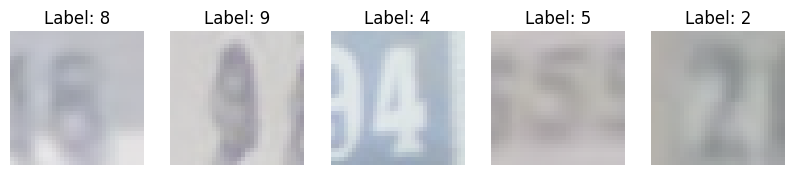

In [4]:
# EDA: Visualize some samples from the dataset
data_iter = iter(train_loader)
num_samples_to_show = 5

images, labels = next(data_iter)

plt.figure(figsize=(10, 2))
for i in range(num_samples_to_show):
    plt.subplot(1, num_samples_to_show, i + 1)
    plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)) * 0.5 + 0.5)
    plt.title(f'Label: {labels[i].item()}')
    plt.axis('off')
plt.show()



=== Train: Klassenverteilung ===
 Klasse  Anzahl  Anteil_%
      1      11     17.19
      2       8     12.50
      3       5      7.81
      4       8     12.50
      5       4      6.25
      6       9     14.06
      7       8     12.50
      8       6      9.38
      9       5      7.81
Imbalance-Ratio (max/min): 2.75

=== Test: Klassenverteilung ===
 Klasse  Anzahl  Anteil_%
      1      11     17.19
      2       8     12.50
      3       5      7.81
      4       8     12.50
      5       4      6.25
      6       9     14.06
      7       8     12.50
      8       6      9.38
      9       5      7.81
Imbalance-Ratio (max/min): 2.75

=== Train: Durchschnittliche Feature-Werte je Klasse ===
        Mean_R  Mean_G  Mean_B  Mean_Intensity
Klasse                                        
0       0.4432  0.4499  0.4772          0.4568
1       0.4370  0.4421  0.4711          0.4501
2       0.4420  0.4473  0.4752          0.4548
3       0.4353  0.4419  0.4711          0.4494
4       0

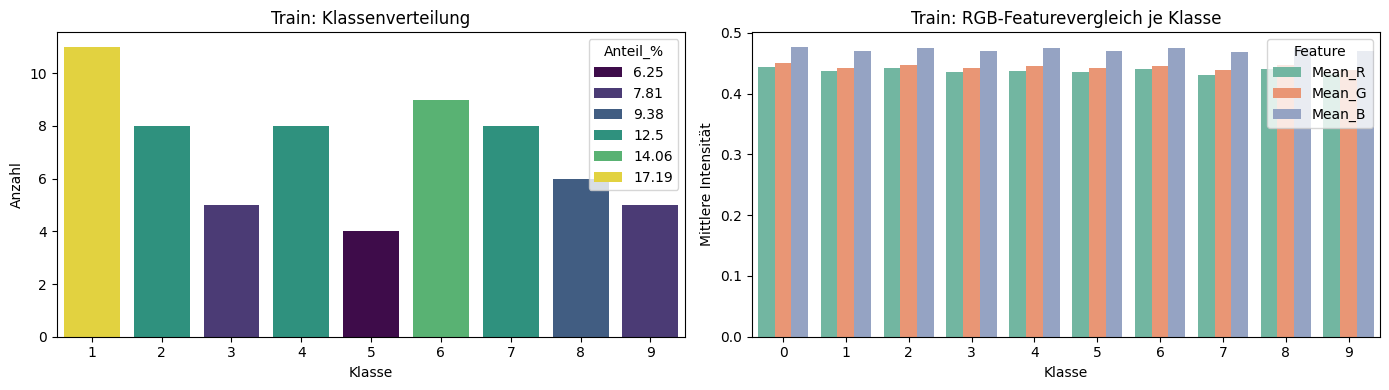


=== Test: Durchschnittliche Feature-Werte je Klasse ===
        Mean_R  Mean_G  Mean_B  Mean_Intensity
Klasse                                        
0       0.4579  0.4578  0.4757          0.4638
1       0.4518  0.4501  0.4653          0.4557
2       0.4483  0.4494  0.4664          0.4547
3       0.4475  0.4496  0.4664          0.4545
4       0.4517  0.4528  0.4702          0.4582
5       0.4530  0.4531  0.4695          0.4585
6       0.4591  0.4591  0.4743          0.4641
7       0.4515  0.4519  0.4688          0.4574
8       0.4582  0.4561  0.4724          0.4623
9       0.4553  0.4551  0.4721          0.4609


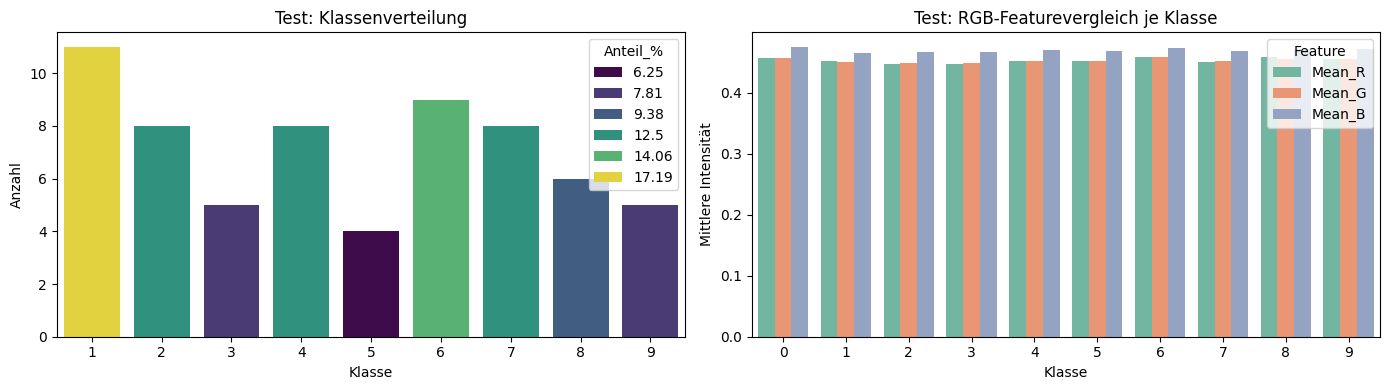

In [5]:
# EDA: Klassen-Balanciertheit + Featurevergleich (RGB-Intensitäten je Klasse)

def prepare_labels(dataset):
    labels = np.array(dataset.labels)
    labels = np.where(labels == 10, 0, labels)
    return labels

def class_dist(labels, split_name="Train"):
    # Klassenverteilung
    class_counts = pd.Series(labels).value_counts().sort_index()
    class_pct = (class_counts / class_counts.sum() * 100).round(2)

    dist_df = pd.DataFrame({
        "Klasse": class_counts.index,
        "Anzahl": class_counts.values,
        "Anteil_%": class_pct.values
    })

    return dist_df, class_counts



def feature_comp(ds, labels, split_name="Train"):
    images = ds.data.astype(np.float32) / 255.0  # (N, C, H, W)

    # Featurevergleich: mittlere RGB-Intensitäten je Bild und Klasse
    mean_r = images[:, 0].mean(axis=(1, 2))
    mean_g = images[:, 1].mean(axis=(1, 2))
    mean_b = images[:, 2].mean(axis=(1, 2))
    mean_intensity = images.mean(axis=(1, 2, 3))

    feat_df = pd.DataFrame({
        "Klasse": labels,
        "Mean_R": mean_r,
        "Mean_G": mean_g,
        "Mean_B": mean_b,
        "Mean_Intensity": mean_intensity
    })

    class_feat = feat_df.groupby("Klasse")[["Mean_R", "Mean_G", "Mean_B", "Mean_Intensity"]].mean()
    print(f"\n=== {split_name}: Durchschnittliche Feature-Werte je Klasse ===")
    print(class_feat.round(4))

    # Visualisierungen
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.barplot(data=dist_df, x="Klasse", y="Anzahl", ax=axes[0], palette="viridis", hue="Anteil_%", dodge=False)
    axes[0].set_title(f"{split_name}: Klassenverteilung")
    axes[0].set_xlabel("Klasse")
    axes[0].set_ylabel("Anzahl")

    class_feat_plot = class_feat.reset_index().melt(
        id_vars="Klasse",
        value_vars=["Mean_R", "Mean_G", "Mean_B"],
        var_name="Feature",
        value_name="Mittelwert"
    )
    sns.barplot(data=class_feat_plot, x="Klasse", y="Mittelwert", hue="Feature", ax=axes[1], palette="Set2",)
    axes[1].set_title(f"{split_name}: RGB-Featurevergleich je Klasse")
    axes[1].set_xlabel("Klasse")
    axes[1].set_ylabel("Mittlere Intensität")
    axes[1].legend(title="Feature")

    plt.tight_layout()
    plt.show()


# EDA für Train und Test
train_labels = prepare_labels(train_loader.dataset)
test_labels = prepare_labels(test_loader.dataset)

for split_name, loader in [("Train", train_loader), ("Test", test_loader)]:
    dist_df, class_counts = class_dist(labels, split_name=split_name)
    print(f"\n=== {split_name}: Klassenverteilung ===")
    print(dist_df.to_string(index=False))
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Imbalance-Ratio (max/min): {imbalance_ratio:.2f}")

feature_comp(train_loader.dataset, train_labels, split_name="Train")
feature_comp(test_loader.dataset, test_labels, split_name="Test")


In [6]:
# Preprocessing der Daten
# calculate mean and std for normalization for each channel
def get_stats(loader):
    sum_, squared_sum, batches = 0, 0, 0
    
    for images, _ in loader:
        # images: [batch_size, 3, 32, 32]
        sum_ += torch.mean(images, dim=[0, 2, 3])
        squared_sum += torch.mean(images**2, dim=[0, 2, 3])
        batches += 1
        
    mean = sum_ / batches
    std = (squared_sum / batches - mean**2)**0.5
    return mean, std

# Berechnung
mean, std = get_stats(train_loader)
print(f"Mean: {mean}")
print(f"Std: {std}")


Mean: tensor([0.4377, 0.4438, 0.4728])
Std: tensor([0.1980, 0.2010, 0.1970])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.111141..0.52355945].


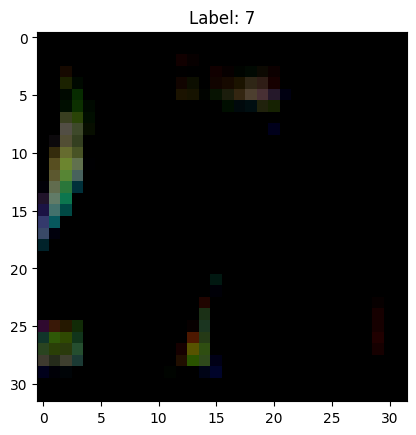

In [7]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_set = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
test_set = datasets.SVHN(root='../data', split='test', download=True, transform=transform)
    
train_loader = DataLoader(train_set, batch_size=4, shuffle=True)
test_loader = DataLoader(test_set, batch_size=4, shuffle=False)

# 2. Visualisieren
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Normalisiertes Bild Anzeigen:
plt.imshow(images[0].permute(1, 2, 0)) # Permute für (H, W, C)
plt.title(f"Label: {labels[0]}")
plt.show()

## Metriken

Da der vorliegende Datensatz eine starke Klassenimbalance aufweist, ist die Accuracy als alleinige Metrik nicht aussagekräftig. Um die Modellleistung über alle Kategorien hinweg objektiv zu bewerten, fokussiere ich mich stattdessen auf den F1-Score sowie Precision und Recall.
Da es sich um ein Multiclass-Problem handelt, wird der CrossEntropyLoss als Verlustfunktion verwendet. Um sicherzustellen, dass auch minderbesetzte Klassen angemessen berücksichtigt werden, kommen bei der Evaluation die Macro-Averages (Macro F1, Macro Precision und Macro Recall) zum Einsatz. 


## 3. Basisfunktionalität

Die Basisfunktionalität wurde wie folgt umgesetzt:

1. **Konfiguration über `RunConfig`**
    - Zentrale Parameter (z. B. `learning_rate`, `batch_size`, `epochs`, `device`) werden in `baseline_config` gebündelt.

2. **Baseline-Training über `run_baseline(...)`**

3. **Experiment-Tracking mit Weights & Biases**
    - Aktiviert über `use_wandb=True` in der Config.
    - Projektname: `DEL`, Run-Name: `baseline-example`.

4. **Auswertung über `WandbRuns`**
    - lädt Runs aus W&B:
    ```python
    wandb_runs = WandbRuns(project="DEL")
    overview_df = wandb_runs.runs_overview(top_k=10)
    ```
    - Zusätzlich vergleichst du Metriken (z. B. `val/loss`) direkt zwischen Runs.

---

## Struktur

```text
src/
├── training.py
│   ├── RunConfig            # Konfigurationsdataclass für Training
│   └── run_baseline(...)    # Führt Baseline-Training + Evaluation aus
├── wandb_tools.py
│   └── WandbRuns            # Laden, Filtern, Vergleichen von W&B-Runs
├── model.py            # Modellarchitekturen
└── metrics.py           # F1, Precision, Recall (Macro)
```

In [8]:
# Overfitting-Test: Kann das Basismodell einen einzelnen Batch auswendig lernen?
from torch.utils.data import DataLoader, TensorDataset
from src.training import FitConfig, run_baseline, RunConfig

batch_images, batch_labels = next(iter(train_loader))
overfit_dataset = TensorDataset(batch_images.clone(), batch_labels.clone())
overfit_loader = DataLoader(overfit_dataset, batch_size=len(overfit_dataset), shuffle=False)

overfit_config = RunConfig(
    learning_rate=5e-2,
    batch_size=len(overfit_dataset),
    epochs=100,
    use_wandb=False,
    wandb_project="DEL",
    run_name="overfit-single-batch",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_seed=42,
    tags=["overfit-check"],
)

overfit_result = run_baseline(
    config=overfit_config,
    fit_config=FitConfig(epochs=100),
    train_loader=overfit_loader,
)

history = overfit_result["history"]
print(f"Final train accuracy: {history['train_accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history['val_accuracy'][-1]:.4f}")
print(f"Final train loss: {history['train_loss'][-1]:.4f}")
print(f"Final val loss: {history['val_loss'][-1]:.4f}")


Final train accuracy: 1.0000
Final val accuracy: 0.0000
Final train loss: 0.0008
Final val loss: 7.3379


## 4. Training des Basismodells

In diesem Abschnitt wird die geforderte Basis-Konfiguration umgesetzt:
- SGD ohne Momentum
- keine Regularisierung (weight decay = 0)
- keine Batch-Normalization
- manuelles Tuning von Lernrate und Batchsize (kein Auto-Search)
- Schätzung des statistischen Fehlers mit Cross-Validation

In [9]:
## vorbereiten der Funktion zum Plotten der Trainingshistorie
def plot_history(history, title_prefix=""):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title(f"{title_prefix}Loss (Cross-Entropy)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_macro_f1"], label="Train Macro-F1")
    axes[1].plot(epochs, history["val_macro_f1"], label="Validation Macro-F1")
    axes[1].plot(epochs, history["val_accuracy"], label="Validation Accuracy", linestyle="--")
    axes[1].set_title(f"{title_prefix}Metriken")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### 4a) Training mit SGD ohne Momentum/Regularisierung/BatchNorm (alle Trainingsdaten)

Hinweis: Es wird auf dem gesamten Trainingsset trainiert. Zur Lernkurven-Überwachung dient das offizielle Testset als Evaluationsset pro Epoche.

In [ ]:
from src.training import run_baseline, RunConfig, FitConfig
 
baseline_config = RunConfig(
    learning_rate=1e-2,
    batch_size=64,
    epochs=15,
    use_wandb=True,
    wandb_project="DEL",
    run_name="baseline-example",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_seed=42,
    tags=["baseline"],
)
 
baseline_result = run_baseline(
    config=baseline_config,
    fit_config=FitConfig(epochs=baseline_config.epochs),
    train_loader=train_loader,
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


0.25.0


wandb: Currently logged in as: lukas-breiter (lukas-breiter-fachhochschule-nordwestschweiz-fhnw) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


epoch,▁▃▅▆█
train/accuracy,▁▆▇██
train/loss,█▃▂▁▁
train/macro_f1,▁▆▇██
train/macro_precision,▁▆▇██
train/macro_recall,▁▆▇██
val/accuracy,▁▄▆▆█
val/loss,█▆▁▂▇
val/macro_f1,▁▄▆▆█
val/macro_precision,▁▆▆▆█
+1,...


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
train/accuracy,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,▁███████████████████
train/macro_f1,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/macro_precision,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/macro_recall,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/accuracy,█▁█████████████▁████
val/loss,▄▇▂▂▃▂▂▆▁▃▄▃▂▄▂█▃▄▄▂
val/macro_f1,█▁█████████████▁████
val/macro_precision,█▁█████████████▁████
+1,...


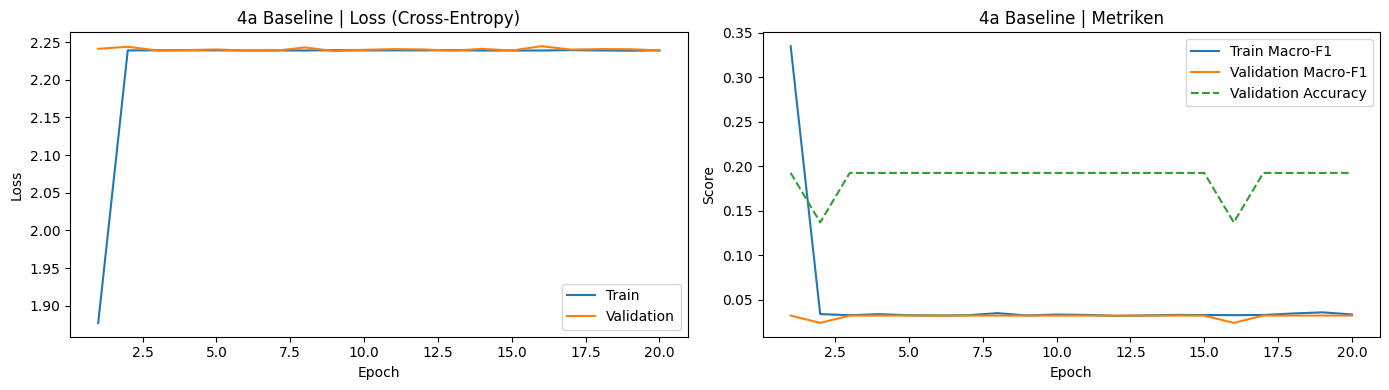

Finale Werte (4a):
val_loss: 2.2391
val_accuracy: 0.1926
val_macro_precision: 0.0193
val_macro_recall: 0.1000
val_macro_f1: 0.0323


In [11]:
baseline_config = RunConfig(
    learning_rate=5e-2,
    batch_size=len(train_loader.dataset),  # Übergeben des gesamten Trainingsdatensatzes als Batch
    epochs=20,
    use_wandb=True,
    wandb_project="DEL",
    wandb_entity="lukas-breiter-fachhochschule-nordwestschweiz-fhnw",
    run_name="Baseline-Training",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_seed=42,
    tags=["baseline"],
)


baseline_result = run_baseline(
    config=baseline_config,
    fit_config=FitConfig(epochs=20),
    train_loader=train_loader,
)


plot_history(baseline_result["history"], title_prefix="4a Baseline | ")

print("Finale Werte (4a):")
print(f"val_loss: {baseline_result['history']['val_loss'][-1]:.4f}")
print(f"val_accuracy: {baseline_result['history']['val_accuracy'][-1]:.4f}")
print(f"val_macro_precision: {baseline_result['history']['val_macro_precision'][-1]:.4f}")
print(f"val_macro_recall: {baseline_result['history']['val_macro_recall'][-1]:.4f}")
print(f"val_macro_f1: {baseline_result['history']['val_macro_f1'][-1]:.4f}")

### 4b) Manuelles Tuning von Lernrate und Batchsize (keine automatische Suche)

Für das Tuning wird ausschließlich die etablierte Funktion `run_baseline(...)` aus `src.training` verwendet.
Es wird ein kleiner manueller Grid getestet (kein Bayes, kein AutoML).

In [12]:
learning_rates = [5e-2, 1e-2, 5e-3]
batch_sizes = [32, 64, 128]
tuning_epochs = 6

tuning_runs = []
histories = {}

for lr, bs in itertools.product(learning_rates, batch_sizes):
    run_name = f"lr={lr}_bs={bs}"
    train_loader_cfg = make_loader(train_set, batch_size=bs, shuffle=True)

    result = run_baseline(
        config=RunConfig(
            learning_rate=lr,
            batch_size=bs,
            epochs=tuning_epochs,
            val_fraction=0.1,
            use_wandb=False,
            wandb_project="DEL",
            run_name=run_name,
            device=DEVICE,
            random_seed=SEED,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
        ),
        fit_config=FitConfig(epochs=tuning_epochs),
        train_loader=train_loader_cfg,
    )

    h = result["history"]
    histories[(lr, bs)] = h
    tuning_runs.append(
        {
            "learning_rate": lr,
            "batch_size": bs,
            "val_loss": h["val_loss"][-1],
            "val_accuracy": h["val_accuracy"][-1],
            "val_macro_precision": h["val_macro_precision"][-1],
            "val_macro_recall": h["val_macro_recall"][-1],
            "val_macro_f1": h["val_macro_f1"][-1],
        }
    )

tuning_df = pd.DataFrame(tuning_runs).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
display(tuning_df)

best_cfg = tuning_df.iloc[0]
best_lr = float(best_cfg["learning_rate"])
best_bs = int(best_cfg["batch_size"])
print(f"Beste Konfiguration nach val_macro_f1: lr={best_lr}, batch_size={best_bs}")

NameError: name 'itertools' is not defined

In [ ]:
def plot_comparison(metric_key, configs, title):
    plt.figure(figsize=(8, 4))
    for (lr, bs) in configs:
        if (lr, bs) not in histories:
            continue
        values = histories[(lr, bs)][metric_key]
        epochs = np.arange(1, len(values) + 1)
        plt.plot(epochs, values, label=f"lr={lr}, bs={bs}")

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(metric_key)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Lernratenvergleich bei fixer Batchsize 64
lr_configs = [(lr, 64) for lr in learning_rates]
plot_comparison("val_loss", lr_configs, "Lernratenvergleich: val_loss (bs=64)")
plot_comparison("val_macro_f1", lr_configs, "Lernratenvergleich: val_macro_f1 (bs=64)")

# Batchsizevergleich bei fixer Lernrate 1e-2
bs_configs = [(1e-2, bs) for bs in batch_sizes]
plot_comparison("val_loss", bs_configs, "Batchsizevergleich: val_loss (lr=1e-2)")
plot_comparison("val_macro_f1", bs_configs, "Batchsizevergleich: val_macro_f1 (lr=1e-2)")

In [ ]:
lr_summary = tuning_df.groupby("learning_rate")[["val_loss", "val_macro_f1", "val_accuracy"]].mean().sort_index()
bs_summary = tuning_df.groupby("batch_size")[["val_loss", "val_macro_f1", "val_accuracy"]].mean().sort_index()

print("Mittelwerte pro Lernrate:")
display(lr_summary)
print("Mittelwerte pro Batchsize:")
display(bs_summary)

print("Diskussion und Theorievergleich:")
print("1) Hohe Lernraten koennen oszillierende oder instabile Loss-Kurven erzeugen.")
print("2) Niedrige Lernraten sind oft stabiler, brauchen aber mehr Epochen.")
print("3) Kleine Batchsizes: noisigere Gradienten, teils bessere Generalisierung.")
print("4) Grosse Batchsizes: glattere Kurven, aber oft empfindlicher bzgl. Lernrate.")
print(f"5) Beste Konfiguration nach val_macro_f1 in diesem manuellen Grid: lr={best_lr}, batch_size={best_bs}.")

Theorievergleich (kurz):
- Sehr große Lernraten können zu Oszillation oder Divergenz führen.
- Sehr kleine Lernraten konvergieren stabiler, benötigen aber meist mehr Epochen.
- Kleinere Batches erzeugen noisigere Gradienten und können besser generalisieren.
- Größere Batches liefern glattere Kurven, benötigen oft passende Lernraten.

Die Einordnung erfolgt anhand der gezeigten Lernkurven (`val_loss`, `val_macro_f1`) sowie der Tabellen (`tuning_df`, `lr_summary`, `bs_summary`).

### 4c) Schätzung des statistischen Fehlers mit Cross-Validation

Die Fold-Splits werden mit `kfold_indices(...)` aus `src.cross_validation` erzeugt.
Trainiert wird pro Fold mit `Trainer` aus `src.training` bei identischem Basismodell und SGD-Setup.

In [ ]:
def cross_validate_baseline(
    dataset,
    learning_rate,
    batch_size,
    epochs=4,
    n_splits=3,
    max_samples=12000,
    seed=SEED,
):
    n_total = min(len(dataset), max_samples)
    base_indices = np.arange(n_total)
    fold_results = []

    for fold_id, (train_idx_rel, val_idx_rel) in enumerate(
        kfold_indices(n_samples=n_total, n_splits=n_splits, shuffle=True, seed=seed),
        start=1,
    ):
        train_idx = base_indices[train_idx_rel]
        val_idx = base_indices[val_idx_rel]

        train_subset = Subset(dataset, train_idx.tolist())
        val_subset = Subset(dataset, val_idx.tolist())

        train_loader_fold = make_loader(train_subset, batch_size=batch_size, shuffle=True, seed=seed + fold_id)
        val_loader_fold = make_loader(val_subset, batch_size=batch_size, shuffle=False)

        model = BaselineCNN(num_classes=10).to(DEVICE)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.SGD(
            model.parameters(),
            lr=learning_rate,
            momentum=0.0,
            weight_decay=0.0,
        )

        trainer = Trainer(
            model=model,
            criterion=criterion,
            optimizer=optimizer,
            device=DEVICE,
            logger=None,
            num_classes=10,
        )

        history = trainer.fit(
            train_loader=train_loader_fold,
            val_loader=val_loader_fold,
            config=FitConfig(epochs=epochs),
        )

        fold_results.append(
            {
                "fold": fold_id,
                "val_loss": history["val_loss"][-1],
                "val_accuracy": history["val_accuracy"][-1],
                "val_macro_precision": history["val_macro_precision"][-1],
                "val_macro_recall": history["val_macro_recall"][-1],
                "val_macro_f1": history["val_macro_f1"][-1],
            }
        )

    return pd.DataFrame(fold_results)

cv_df = cross_validate_baseline(
    dataset=train_set,
    learning_rate=best_lr,
    batch_size=best_bs,
    epochs=4,
    n_splits=3,
    max_samples=12000,
    seed=SEED,
)

display(cv_df)

metrics_for_error = ["val_loss", "val_accuracy", "val_macro_precision", "val_macro_recall", "val_macro_f1"]
summary_rows = []
for metric in metrics_for_error:
    mean_val, std_val = mean_and_std(cv_df[metric].tolist())
    se_val = std_val / sqrt(len(cv_df))
    summary_rows.append({
        "metric": metric,
        "mean": mean_val,
        "std": std_val,
        "standard_error": se_val,
    })

cv_summary_df = pd.DataFrame(summary_rows)
display(cv_summary_df)

print("Statistische Fehlerschaetzung:")
for _, row in cv_summary_df.iterrows():
    print(f"{row['metric']}: {row['mean']:.4f} +/- {row['std']:.4f} (SE={row['standard_error']:.4f})")

Interpretation:
- Die Mittelwerte sind die erwartete Leistung der gewählten Konfiguration.
- Die Standardabweichung (std) beschreibt die Streuung zwischen den Folds.
- Der Standardfehler (SE = std / sqrt(K)) schätzt die Unsicherheit des Mittelwerts.